# Studio Proyek 3 - Fine-Tuning Transformer Pretrained untuk NLP
Anggota:
- Muhamad Rafi Ilham (123140173)
- Cikal Galih Nur Arifin (123140109)
- Bagas Dwi Ajitya (123140181)

## 1. Rancangan Eksperimen

### 1.1 Dataset
Dataset yang digunakan adalah SmSA dari IndoNLU untuk klasifikasi sentimen teks Bahasa Indonesia. Dataset memiliki tiga kelas, yaitu positif, netral, dan negatif.

Dataset dipilih karena sesuai dengan tugas klasifikasi sentimen Bahasa Indonesia. Eksperimen menggunakan pembagian resmi train, validation, dan test. Data dibersihkan dari duplikasi dan konflik label sebelum digunakan.

### 1.2 Hipotesis
- H1: IndoBERT diperkirakan menghasilkan Macro-F1 lebih tinggi karena pretrained pada teks Bahasa Indonesia.
- H2: DistilBERT diperkirakan memiliki waktu training dan inferensi lebih rendah dibandingkan BERT.
- H3: Full fine-tuning diperkirakan menghasilkan Macro-F1 lebih tinggi dibandingkan partial freezing, tetapi membutuhkan lebih banyak komputasi.

### 1.3 Matriks Eksperimen
| Backbone | Full Fine-Tuning | Partial Freezing |
|---|---|---|
| BERT Multilingual | 3 seed | 3 seed |
| DistilBERT Multilingual | 3 seed | 3 seed |
| IndoBERT | 3 seed | 3 seed |

Total eksperimen: 3 backbone × 2 strategi × 3 seed = 18 run.

### 1.4 Konfigurasi Eksperimen
| Parameter | Nilai |
|---|---|
| Dataset | SmSA |
| Max length | 128 |
| Batch size | 16 |
| Epoch | 3 |
| Random seed | 42, 123, 2026 |
| Learning rate full | 2e-5 |
| Learning rate partial | 3e-5 |
| Platform | Google Colab GPU |
| Evaluasi | Accuracy dan Macro-F1 |
| Efisiensi | Waktu training, waktu inferensi, jumlah parameter, dan memori puncak |

### 1.5 Strategi Fine-Tuning
Semua backbone menggunakan classification head dengan tiga keluaran kelas.

Full fine-tuning melatih seluruh parameter model. Partial freezing membekukan embedding dan separuh lapisan encoder awal, sedangkan lapisan sisanya dan classification head tetap dilatih.

### 1.6 Rencana Evaluasi
Perbandingan dilakukan menggunakan protokol eksperimen yang sama untuk setiap backbone. Hasil dilaporkan berdasarkan rata-rata dan standar deviasi dari tiga seed. Waktu inferensi dibandingkan pada perangkat dan sesi yang sama.

## 2. Persiapan Dataset
### 2.1 Menghubungkan Google Drive
Google Drive digunakan sebagai tempat penyimpanan dataset dan hasil eksperimen agar seluruh anggota kelompok dapat mengakses file yang sama.

In [ ]:
from google.colab import drive
from pathlib import Path

# Menghubungkan Google Drive
drive.mount('/content/drive')

# Folder utama proyek
folder_utama = Path('/content/drive/MyDrive/Studio3')

# Membuat folder kebutuhan proyek
folder_dataset = folder_utama / '02_Dataset'
folder_hasil = folder_utama / '03_Hasil_Eksperimen'
folder_evaluasi = folder_utama / '04_Evaluasi'
folder_laporan = folder_utama / '05_Laporan_Presentasi'

for folder in [folder_dataset, folder_hasil, folder_evaluasi, folder_laporan]:
    folder.mkdir(parents=True, exist_ok=True)

print("Google Drive berhasil terhubung!")
print("Folder proyek:", folder_utama)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive berhasil terhubung!
Folder proyek: /content/drive/MyDrive/Studio3


### 2.2 Memuat dan Membersihkan Dataset SmSA
Dataset SmSA merupakan bagian dari benchmark IndoNLU yang digunakan untuk klasifikasi sentimen teks berbahasa Indonesia. Dataset terdiri dari tiga kelas sentimen, yaitu negative, neutral, dan positive.

Data diperoleh dari repository resmi IndoNLU dan menggunakan pembagian train, validation, serta test. Sebelum digunakan, dilakukan pemeriksaan data kosong, duplikasi, dan konflik label untuk mengurangi risiko kebocoran data selama eksperimen.

Jumlah dataset awal:
Train: 11000
Valid: 1260
Test : 500


,text,label
0,warung ini dimiliki oleh pengusaha pabrik tahu...,positive
1,mohon ulama lurus dan k212 mmbri hujjah partai...,neutral
2,lokasi strategis di jalan sumatera bandung . t...,positive
3,betapa bahagia nya diri ini saat unboxing pake...,positive
4,duh . jadi mahasiswa jangan sombong dong . kas...,negative



Jumlah data setelah cleaning:
Train: 10919
Valid: 1260
Test : 500
Teks konflik: 0


,Train,Validation,Test
label,,,
negative,3407,394,204
neutral,1136,131,88
positive,6376,735,208


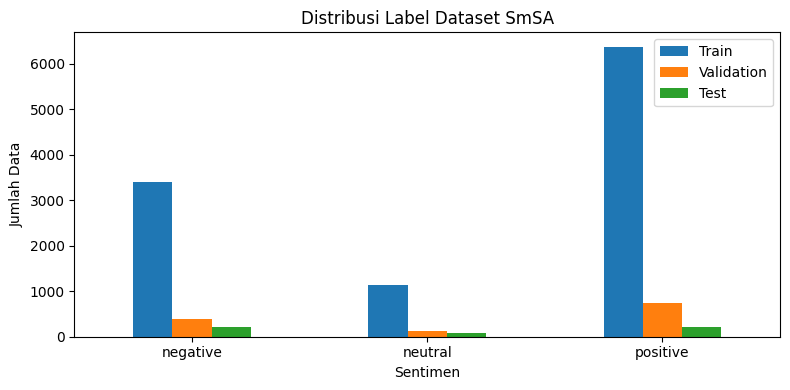


Dataset berhasil disimpan ke Google Drive!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from urllib.request import urlretrieve

# Sumber dataset resmi IndoNLU
base_url = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/"

nama_file = {
    "train": "train_preprocess.tsv",
    "valid": "valid_preprocess.tsv",
    "test": "test_preprocess.tsv"
}

# Download dan simpan dataset asli ke Drive
data = {}

for bagian, nama in nama_file.items():
    lokasi = folder_dataset / nama

    if not lokasi.exists():
        urlretrieve(base_url + nama, lokasi)

    data[bagian] = pd.read_csv(
        lokasi, sep="\t", header=None,
        names=["text", "label"]
    )

train_df = data["train"]
valid_df = data["valid"]
test_df = data["test"]

print("Jumlah dataset awal:")
print("Train:", len(train_df))
print("Valid:", len(valid_df))
print("Test :", len(test_df))

display(train_df.head())

# Membersihkan data
label_valid = ["negative", "neutral", "positive"]

def bersihkan_data(df):
    df = df.copy()
    df = df.dropna(subset=["text", "label"])

    df["text"] = df["text"].astype(str).str.strip()
    df["label"] = df["label"].astype(str).str.strip()

    df = df[
        (df["text"] != "") &
        (df["label"].isin(label_valid))
    ]

    df = df.drop_duplicates(subset=["text", "label"])
    return df.reset_index(drop=True)

train_df = bersihkan_data(train_df)
valid_df = bersihkan_data(valid_df)
test_df = bersihkan_data(test_df)

# Menghapus teks dengan label bertentangan
gabungan = pd.concat([train_df, valid_df, test_df])

konflik = gabungan.groupby("text")["label"].nunique()
teks_konflik = set(konflik[konflik > 1].index)

train_df = train_df[~train_df["text"].isin(teks_konflik)]
valid_df = valid_df[~valid_df["text"].isin(teks_konflik)]
test_df = test_df[~test_df["text"].isin(teks_konflik)]

# Menghapus duplikat teks dalam tiap split
train_df = train_df.drop_duplicates(subset=["text"])
valid_df = valid_df.drop_duplicates(subset=["text"])
test_df = test_df.drop_duplicates(subset=["text"])

# Menghindari kebocoran antar split
valid_df = valid_df[
    ~valid_df["text"].isin(test_df["text"])
]

train_df = train_df[
    ~train_df["text"].isin(
        set(valid_df["text"]) | set(test_df["text"])
    )
]

train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Memastikan split tidak memiliki teks yang sama
assert set(train_df["text"]).isdisjoint(valid_df["text"])
assert set(train_df["text"]).isdisjoint(test_df["text"])
assert set(valid_df["text"]).isdisjoint(test_df["text"])

# Mengubah label menjadi angka
label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {v: k for k, v in label2id.items()}

for df in [train_df, valid_df, test_df]:
    df["label_id"] = df["label"].map(label2id).astype(int)

# Menampilkan jumlah data setelah cleaning
print("\nJumlah data setelah cleaning:")
print("Train:", len(train_df))
print("Valid:", len(valid_df))
print("Test :", len(test_df))
print("Teks konflik:", len(teks_konflik))

# Distribusi label
distribusi = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": valid_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).reindex(label_valid).fillna(0).astype(int)

display(distribusi)

distribusi.plot(kind="bar", figsize=(8, 4))
plt.title("Distribusi Label Dataset SmSA")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Menyimpan data bersih ke Drive
train_df.to_csv(folder_dataset / "smsa_train.csv", index=False)
valid_df.to_csv(folder_dataset / "smsa_valid.csv", index=False)
test_df.to_csv(folder_dataset / "smsa_test.csv", index=False)

print("\nDataset berhasil disimpan ke Google Drive!")

## 3. Tokenisasi dan Persiapan Model Transformer
### 3.1 Library dan Konfigurasi Eksperimen
Pada tahap ini, digunakan library PyTorch dan Hugging Face Transformers untuk mempersiapkan model pretrained yang akan digunakan dalam klasifikasi sentimen.

Eksperimen menggunakan tiga backbone, yaitu BERT Multilingual, DistilBERT Multilingual, dan IndoBERT. Setiap model akan diuji menggunakan konfigurasi yang telah ditentukan pada rancangan eksperimen.

In [ ]:
# Instal ulang Transformers tanpa mengubah PyTorch CUDA
!pip uninstall -y transformers
!pip install --no-cache-dir --no-deps transformers==4.57.3

Found existing installation: transformers 4.57.3
Uninstalling transformers-4.57.3:
  Successfully uninstalled transformers-4.57.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 10.8 MB/s  0:00:01


In [ ]:
import torch
import gc
import pandas as pd

from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    set_seed
)

# Konfigurasi eksperimen
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 3
SEEDS = [42, 123, 2026]

# Backbone pretrained
daftar_model = {
    "BERT": "bert-base-multilingual-cased",
    "DistilBERT": "distilbert-base-multilingual-cased",
    "IndoBERT": "indobenchmark/indobert-base-p1"
}

# Label sentimen
label2id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}
id2label = {v: k for k, v in label2id.items()}

# Memuat dataset bersih dari Google Drive
train_df = pd.read_csv(folder_dataset / "smsa_train.csv")
valid_df = pd.read_csv(folder_dataset / "smsa_valid.csv")
test_df = pd.read_csv(folder_dataset / "smsa_test.csv")

# Memeriksa GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Jumlah data train:", len(train_df))
print("Jumlah data valid:", len(valid_df))
print("Jumlah data test :", len(test_df))

print("\nDaftar Backbone:")
for nama, model_id in daftar_model.items():
    print(nama, ":", model_id)

Device: cuda
Jumlah data train: 10919
Jumlah data valid: 1260
Jumlah data test : 500

Daftar Backbone:
BERT : bert-base-multilingual-cased
DistilBERT : distilbert-base-multilingual-cased
IndoBERT : indobenchmark/indobert-base-p1


### 3.2 Tokenisasi Dataset
Tokenisasi dilakukan untuk mengubah teks menjadi representasi numerik agar dapat diproses oleh model Transformer.

Setiap backbone menggunakan tokenizer pretrained yang sesuai dengan modelnya. Proses tokenisasi menggunakan max_length 128, padding, dan truncation untuk menyeragamkan panjang input.

In [ ]:
from transformers import BertTokenizerFast, DistilBertTokenizerFast

# Membuat dataset untuk Transformer
class SmSADataset(Dataset):
    def __init__(self, dataframe, tokenizer):
        teks = dataframe["text"].astype(str).tolist()

        self.encodings = tokenizer(
            teks,
            padding="max_length",
            truncation=True,
            max_length=MAX_LENGTH
        )

        self.labels = dataframe["label_id"].astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(value[idx], dtype=torch.long)
            for key, value in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx], dtype=torch.long
        )

        return item


# Menyiapkan tokenizer sesuai backbone
def siapkan_dataset(model_id):

    if model_id == daftar_model["DistilBERT"]:
        tokenizer = DistilBertTokenizerFast.from_pretrained(model_id)
    else:
        tokenizer = BertTokenizerFast.from_pretrained(model_id)

    train_data = SmSADataset(train_df, tokenizer)
    valid_data = SmSADataset(valid_df, tokenizer)
    test_data = SmSADataset(test_df, tokenizer)

    return tokenizer, train_data, valid_data, test_data

print("Fungsi tokenisasi berhasil dibuat.")

Fungsi tokenisasi berhasil dibuat.


### 3.3 Implementasi Backbone dan Strategi Fine-Tuning

Model pretrained dimuat menggunakan AutoModelForSequenceClassification dengan tiga kelas output, yaitu negative, neutral, dan positive.

Dua strategi yang digunakan adalah full fine-tuning dan partial freezing.

Pada full fine-tuning, seluruh parameter model dilatih. Sementara pada partial freezing, embedding dan separuh lapisan encoder awal dibekukan sehingga hanya sebagian parameter yang diperbarui selama pelatihan.

Strategi ini digunakan untuk membandingkan kinerja model terhadap kebutuhan komputasi.

In [ ]:
# Fungsi mengatur strategi fine-tuning
def atur_strategi(model, strategi):

    # Semua parameter aktif terlebih dahulu
    for param in model.parameters():
        param.requires_grad = True

    if strategi == "full":
        pass

    elif strategi == "partial":
        backbone = model.base_model

        # Membekukan embedding
        for param in backbone.embeddings.parameters():
            param.requires_grad = False

        # Mengambil lapisan encoder
        if hasattr(backbone, "encoder"):
            layers = backbone.encoder.layer
        elif hasattr(backbone, "transformer"):
            layers = backbone.transformer.layer
        else:
            raise ValueError("Arsitektur tidak dikenali")

        # Membekukan separuh lapisan awal
        jumlah_beku = len(layers) // 2

        for layer in layers[:jumlah_beku]:
            for param in layer.parameters():
                param.requires_grad = False

    else:
        raise ValueError("Strategi tidak dikenal")

    return model


# Fungsi memuat model pretrained
def buat_model(model_id, strategi):
    model = AutoModelForSequenceClassification.from_pretrained(
        model_id,
        num_labels=3,
        id2label=id2label,
        label2id=label2id
    )

    model = atur_strategi(model, strategi)

    return model


# Fungsi menghitung parameter
def hitung_parameter(model):
    total = sum(p.numel() for p in model.parameters())

    dilatih = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    return total, dilatih

print("Fungsi backbone dan strategi berhasil dibuat.")

Fungsi backbone dan strategi berhasil dibuat.


### 3.4 Pengujian Awal Model

Pengujian awal dilakukan menggunakan DistilBERT untuk memastikan proses tokenisasi, pemuatan model pretrained, dan pengaturan strategi fine-tuning dapat berjalan dengan baik.

Pengujian juga dilakukan untuk membandingkan jumlah parameter yang dilatih pada strategi full fine-tuning dan partial freezing sebelum seluruh eksperimen dijalankan.

In [ ]:
import transformers
from transformers import AutoTokenizer

print("Versi Transformers:", transformers.__version__)

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-multilingual-cased",
    use_fast=True
)

hasil = tokenizer(
    "Pelayanannya sangat bagus",
    padding="max_length",
    truncation=True,
    max_length=128
)

print("Tokenizer:", type(tokenizer).__name__)
print("Jumlah token:", len(hasil["input_ids"]))
print("Tokenisasi berhasil!")

Versi Transformers: 4.57.3


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Tokenizer: DistilBertTokenizerFast
Jumlah token: 128
Tokenisasi berhasil!


In [ ]:
# Mengatur seed awal
set_seed(42)

# Menggunakan DistilBERT untuk pengujian
model_id = daftar_model["DistilBERT"]

tokenizer, train_data, valid_data, test_data = siapkan_dataset(
    model_id
)

print("Jumlah data tokenisasi:")
print("Train:", len(train_data))
print("Valid:", len(valid_data))
print("Test :", len(test_data))

# Full fine-tuning
model = buat_model(model_id, "full")
total, parameter_full = hitung_parameter(model)

print("\nFull Fine-Tuning")
print("Total parameter:", f"{total:,}")
print("Parameter dilatih:", f"{parameter_full:,}")

# Partial freezing
model = atur_strategi(model, "partial")
_, parameter_partial = hitung_parameter(model)

print("\nPartial Freezing")
print("Total parameter:", f"{total:,}")
print("Parameter dilatih:", f"{parameter_partial:,}")

assert parameter_partial < parameter_full

# Pengujian forward pass
model = model.to(device)
loader = DataLoader(valid_data, batch_size=2)
batch = next(iter(loader))

batch = {
    key: value.to(device)
    for key, value in batch.items()
}

model.eval()

with torch.no_grad():
    output = model(**batch)

print("\nBentuk logits:", output.logits.shape)
print("Loss:", output.loss.item())

assert output.logits.shape == (2, 3)

print("\nPengujian model berhasil!")

# Membersihkan memori
del model, loader, batch, output
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Jumlah data tokenisasi:
Train: 10919
Valid: 1260
Test : 500


model.safetensors:   0%|          | 0.00/542M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Full Fine-Tuning
Total parameter: 135,326,979
Parameter dilatih: 135,326,979

Partial Freezing
Total parameter: 135,326,979
Parameter dilatih: 21,856,515

Bentuk logits: torch.Size([2, 3])
Loss: 1.078878402709961

Pengujian model berhasil!


In [ ]:
import time
import gc
import torch
import pandas as pd

from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# Learning rate setiap strategi
learning_rates = {
    "full": 2e-5,
    "partial": 3e-5
}

# Fungsi evaluasi
def evaluasi_model(model, loader, ukur_waktu=False):
    model.eval()
    y_true, y_pred = [], []

    if ukur_waktu:
        contoh = next(iter(loader))
        contoh = {k: v.to(device) for k, v in contoh.items()}

        with torch.inference_mode():
            model(**contoh)

        torch.cuda.synchronize()
        mulai = time.perf_counter()

    with torch.inference_mode():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}

            output = model(**batch)
            prediksi = output.logits.argmax(dim=-1)

            y_true.extend(batch["labels"].cpu().tolist())
            y_pred.extend(prediksi.cpu().tolist())

    waktu_inferensi = None

    if ukur_waktu:
        torch.cuda.synchronize()
        durasi = time.perf_counter() - mulai
        waktu_inferensi = durasi * 1000 / len(y_true)

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    return accuracy, macro_f1, waktu_inferensi


# Fungsi training untuk satu eksperimen
def jalankan_training(nama_model, strategi, seed,
                      train_data, valid_data, test_data):

    set_seed(seed)

    model = buat_model(daftar_model[nama_model], strategi)
    model = model.to(device)

    total_param, param_dilatih = hitung_parameter(model)

    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_data, batch_size=BATCH_SIZE,
        shuffle=True, generator=generator
    )
    valid_loader = DataLoader(
        valid_data, batch_size=BATCH_SIZE
    )
    test_loader = DataLoader(
        test_data, batch_size=BATCH_SIZE
    )

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rates[strategi]
    )

    torch.cuda.reset_peak_memory_stats()

    best_f1 = -1
    best_state = None
    waktu_latih = 0

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0

        torch.cuda.synchronize()
        mulai = time.perf_counter()

        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}

            optimizer.zero_grad()
            output = model(**batch)
            loss = output.loss

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )
            optimizer.step()

            total_loss += loss.item()

        torch.cuda.synchronize()
        waktu_latih += time.perf_counter() - mulai

        val_acc, val_f1, _ = evaluasi_model(
            model, valid_loader
        )

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Loss: {total_loss/len(train_loader):.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    # Mengembalikan bobot terbaik
    model.load_state_dict(best_state)

    test_acc, test_f1, waktu_inferensi = evaluasi_model(
        model, test_loader, ukur_waktu=True
    )

    memori_puncak = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
    )

    hasil = {
        "backbone": nama_model,
        "strategi": strategi,
        "seed": seed,
        "accuracy": test_acc,
        "macro_f1": test_f1,
        "waktu_latih_detik": waktu_latih,
        "inferensi_ms_per_kalimat": waktu_inferensi,
        "parameter_total": total_param,
        "parameter_dilatih": param_dilatih,
        "memori_puncak_mb": memori_puncak,
        "best_val_f1": best_f1
    }

    del model, optimizer, best_state
    gc.collect()
    torch.cuda.empty_cache()

    return hasil

print("Fungsi training dan evaluasi siap.")

Fungsi training dan evaluasi siap.



## 4. Pelatihan dan Evaluasi Model

Pelatihan dilakukan terhadap tiga backbone Transformer, yaitu BERT Multilingual, DistilBERT Multilingual, dan IndoBERT. Setiap backbone diuji menggunakan dua strategi fine-tuning, yaitu full fine-tuning dan partial freezing.

Setiap kombinasi eksperimen dijalankan menggunakan tiga random seed (42, 123, dan 2026) untuk mengamati konsistensi hasil pelatihan. Proses training menggunakan tiga epoch dengan batch size 16 dan max length 128.

Evaluasi dilakukan menggunakan Accuracy dan Macro-F1. Selain kinerja klasifikasi, pengukuran juga mencakup waktu training, waktu inferensi, jumlah parameter yang dilatih, serta penggunaan memori GPU.


In [ ]:
import hashlib
import json

# Rafi gunakan "rafi", Cikal gunakan "cikal"
PELAKSANA = "rafi"

pembagian_run = {
    "rafi": [
        ("BERT", "full"),
        ("BERT", "partial"),
        ("DistilBERT", "full")
    ],
    "cikal": [
        ("IndoBERT", "full"),
        ("IndoBERT", "partial"),
        ("DistilBERT", "partial")
    ]
}

# Identitas konfigurasi eksperimen
konfigurasi = {
    "dataset": "smsa",
    "model": daftar_model,
    "strategi": learning_rates,
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "seeds": SEEDS,
    "jumlah_train": len(train_df),
    "jumlah_valid": len(valid_df),
    "jumlah_test": len(test_df)
}

kode = hashlib.sha256(
    json.dumps(konfigurasi, sort_keys=True).encode()
).hexdigest()[:8]

folder_hasil.mkdir(parents=True, exist_ok=True)
file_hasil = folder_hasil / f"run_{PELAKSANA}_{kode}.csv"

# Membaca hasil sebelumnya jika tersedia
if file_hasil.exists():
    hasil_df = pd.read_csv(file_hasil)
else:
    hasil_df = pd.DataFrame()

for nama_model, strategi in pembagian_run[PELAKSANA]:

    tokenizer, train_data, valid_data, test_data = (
        siapkan_dataset(daftar_model[nama_model])
    )

    for seed in SEEDS:

        if not hasil_df.empty:
            sudah_ada = (
                (hasil_df["backbone"] == nama_model) &
                (hasil_df["strategi"] == strategi) &
                (hasil_df["seed"] == seed)
            ).any()

            if sudah_ada:
                print("Run sudah ada:", nama_model, strategi, seed)
                continue

        print(f"\nModel: {nama_model}")
        print(f"Strategi: {strategi}")
        print(f"Seed: {seed}")

        hasil = jalankan_training(
            nama_model, strategi, seed,
            train_data, valid_data, test_data
        )

        hasil["pelaksana"] = PELAKSANA
        hasil["gpu"] = torch.cuda.get_device_name(0)
        hasil["kode"] = kode

        hasil_df = pd.concat(
            [hasil_df, pd.DataFrame([hasil])],
            ignore_index=True
        )

        # Simpan setiap selesai satu run
        hasil_df.to_csv(file_hasil, index=False)

        print(
            f"Selesai | Accuracy: {hasil['accuracy']:.4f} "
            f"| Macro-F1: {hasil['macro_f1']:.4f}"
        )

    del tokenizer, train_data, valid_data, test_data
    gc.collect()

print("\nEksperimen bagian", PELAKSANA, "selesai.")
print("Jumlah run tersimpan:", len(hasil_df))
print("Lokasi:", file_hasil)

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]


Model: BERT
Strategi: full
Seed: 42


model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

... (14 outputs left out)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/3 | Loss: 0.4564 | Val F1: 0.8479
Epoch 2/3 | Loss: 0.2577 | Val F1: 0.8566
Epoch 3/3 | Loss: 0.1729 | Val F1: 0.8544
Selesai | Accuracy: 0.8360 | Macro-F1: 0.8018

Model: DistilBERT
Strategi: full
Seed: 2026


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/3 | Loss: 0.4656 | Val F1: 0.8425
Epoch 2/3 | Loss: 0.2600 | Val F1: 0.8552
Epoch 3/3 | Loss: 0.1714 | Val F1: 0.8589
Selesai | Accuracy: 0.8260 | Macro-F1: 0.7788

Eksperimen bagian rafi selesai.
Jumlah run tersimpan: 9
Lokasi: /content/drive/MyDrive/Studio3/03_Hasil_Eksperimen/run_rafi_d7adf624.csv


In [ ]:
# Memeriksa hasil training anggota kelompok
file_rafi = folder_hasil / f"run_rafi_{kode}.csv"
file_cikal = folder_hasil / f"run_cikal_{kode}.csv"

print("File hasil Rafi:", file_rafi.exists())
print("File hasil Cikal:", file_cikal.exists())

if file_rafi.exists():
    hasil_rafi = pd.read_csv(file_rafi)
    print("\nJumlah run Rafi:", len(hasil_rafi))
    display(hasil_rafi)

if file_cikal.exists():
    hasil_cikal = pd.read_csv(file_cikal)
    print("\nJumlah run Cikal:", len(hasil_cikal))
    display(hasil_cikal)
else:
    print("\nHasil Cikal belum tersedia.")

File hasil Rafi: True
File hasil Cikal: True

Jumlah run Rafi: 9


,backbone,strategi,seed,accuracy,macro_f1,waktu_latih_detik,inferensi_ms_per_kalimat,parameter_total,parameter_dilatih,memori_puncak_mb,best_val_f1,pelaksana,gpu,kode
0,BERT,full,42,0.862,0.817592,834.790748,8.257520,177855747,177855747,3429.750977,0.873580,rafi,Tesla T4,d7adf624
1,BERT,full,123,0.858,0.809235,838.525024,8.203440,177855747,177855747,3423.500977,0.860120,rafi,Tesla T4,d7adf624
2,BERT,full,2026,0.832,0.790541,837.836547,8.173700,177855747,177855747,3427.500977,0.873574,rafi,Tesla T4,d7adf624
3,BERT,partial,42,0.798,0.740890,517.112298,8.232118,177855747,43120131,1677.774902,0.841652,rafi,Tesla T4,d7adf624
4,BERT,partial,123,0.812,0.771296,516.739961,8.186746,177855747,43120131,1676.024902,0.845843,rafi,Tesla T4,d7adf624
5,BERT,partial,2026,0.794,0.744337,516.759125,8.227794,177855747,43120131,1676.274902,0.848796,rafi,Tesla T4,d7adf624
6,DistilBERT,full,42,0.840,0.796975,450.996269,4.163550,135326979,135326979,2607.193359,0.865549,rafi,Tesla T4,d7adf624
7,DistilBERT,full,123,0.836,0.801756,450.277907,4.133547,135326979,135326979,2610.943359,0.856645,rafi,Tesla T4,d7adf624
8,DistilBERT,full,2026,0.826,0.778783,449.772511,4.094060,135326979,135326979,2608.943359,0.858856,rafi,Tesla T4,d7adf624



Jumlah run Cikal: 9


,backbone,strategi,seed,accuracy,macro_f1,waktu_latih_detik,inferensi_ms_per_kalimat,parameter_total,parameter_dilatih,memori_puncak_mb,best_val_f1,pelaksana,gpu,kode
0,IndoBERT,full,42,0.918,0.899022,733.726947,7.158584,124443651,124443651,2695.145996,0.907998,cikal,Tesla T4,d7adf624
1,IndoBERT,full,123,0.906,0.878413,733.441716,7.155718,124443651,124443651,2696.520996,0.913489,cikal,Tesla T4,d7adf624
2,IndoBERT,full,2026,0.890,0.860218,733.792204,7.159778,124443651,124443651,2696.520996,0.908473,cikal,Tesla T4,d7adf624
3,IndoBERT,partial,42,0.904,0.870967,468.687484,7.141540,124443651,43120131,1473.524902,0.912150,cikal,Tesla T4,d7adf624
4,IndoBERT,partial,123,0.928,0.909708,469.088792,7.162743,124443651,43120131,1472.774902,0.902569,cikal,Tesla T4,d7adf624
5,IndoBERT,partial,2026,0.924,0.900558,468.952439,7.172350,124443651,43120131,1473.274902,0.912720,cikal,Tesla T4,d7adf624
6,DistilBERT,partial,42,0.784,0.734808,232.583221,3.607062,135326979,21856515,1048.167480,0.827500,cikal,Tesla T4,d7adf624
7,DistilBERT,partial,123,0.820,0.769817,232.521820,3.623563,135326979,21856515,1047.667480,0.825690,cikal,Tesla T4,d7adf624
8,DistilBERT,partial,2026,0.768,0.748230,232.506565,3.602127,135326979,21856515,1046.917480,0.844615,cikal,Tesla T4,d7adf624



## 5. Rekap Hasil Eksperimen

Hasil pelatihan dari digabung untuk memperoleh keseluruhan hasil eksperimen. Penggabungan dilakukan terhadap 18 run yang mencakup enam kombinasi backbone dan strategi fine-tuning.

Setiap kombinasi memiliki tiga hasil berdasarkan random seed yang berbeda. Selanjutnya, dilakukan perhitungan rata-rata dan standar deviasi untuk setiap metrik evaluasi guna memperoleh gambaran kinerja dan efisiensi masing-masing model.

Hasil penggabungan disimpan dalam bentuk CSV sebagai dasar analisis dan visualisasi.


In [ ]:
# Menggabungkan hasil eksperimen
hasil_rafi = pd.read_csv(file_rafi)
hasil_cikal = pd.read_csv(file_cikal)

hasil_semua = pd.concat(
    [hasil_rafi, hasil_cikal],
    ignore_index=True
)

# Memeriksa kelengkapan kombinasi eksperimen
kolom_kunci = ["backbone", "strategi", "seed"]

kombinasi_wajib = {
    (model, strategi, seed)
    for model in daftar_model
    for strategi in ["full", "partial"]
    for seed in SEEDS
}

kombinasi_hasil = set(
    tuple(baris)
    for baris in hasil_semua[kolom_kunci].itertuples(
        index=False, name=None
    )
)

assert len(hasil_semua) == 18, "Jumlah run belum 18!"
assert not hasil_semua.duplicated(kolom_kunci).any(), \
    "Ada eksperimen duplikat!"
assert kombinasi_hasil == kombinasi_wajib, \
    "Ada kombinasi eksperimen yang belum lengkap!"

assert hasil_semua["kode"].nunique() == 1, \
    "Konfigurasi Rafi dan Cikal berbeda!"

# Menyimpan seluruh hasil
file_gabungan = folder_hasil / f"hasil_smsa_{kode}.csv"
hasil_semua.to_csv(file_gabungan, index=False)

# Menghitung rata-rata dan standar deviasi
metrik = [
    "accuracy",
    "macro_f1",
    "waktu_latih_detik",
    "inferensi_ms_per_kalimat",
    "parameter_total",
    "parameter_dilatih",
    "memori_puncak_mb"
]

rekap = hasil_semua.groupby(
    ["backbone", "strategi"]
)[metrik].agg(["mean", "std"])

rekap.columns = [
    f"{nama}_{stat}"
    for nama, stat in rekap.columns
]

rekap = rekap.reset_index()

# Menyimpan rekap
file_rekap = folder_hasil / f"rekap_agregat_smsa_{kode}.csv"
rekap.to_csv(file_rekap, index=False)

print("Total eksperimen:", len(hasil_semua))
print("Jumlah kombinasi:", len(rekap))
print("\nRekap Accuracy dan Macro-F1:")

display(rekap[
    ["backbone", "strategi",
     "accuracy_mean", "accuracy_std",
     "macro_f1_mean", "macro_f1_std"]
].round(4))

print("\nFile berhasil disimpan:")
print(file_gabungan.name)
print(file_rekap.name)

Total eksperimen: 18
Jumlah kombinasi: 6

Rekap Accuracy dan Macro-F1:


,backbone,strategi,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
0,BERT,full,0.8507,0.0163,0.8058,0.0139
1,BERT,partial,0.8013,0.0095,0.7522,0.0166
2,DistilBERT,full,0.8340,0.0072,0.7925,0.0121
3,DistilBERT,partial,0.7907,0.0266,0.7510,0.0177
4,IndoBERT,full,0.9047,0.0140,0.8792,0.0194
5,IndoBERT,partial,0.9187,0.0129,0.8937,0.0202



File berhasil disimpan:
hasil_smsa_d7adf624.csv
rekap_agregat_smsa_d7adf624.csv



## 6. Visualisasi Hasil Eksperimen

Visualisasi digunakan untuk mempermudah perbandingan kinerja dan efisiensi setiap backbone berdasarkan strategi fine-tuning yang diterapkan.

Visualisasi mencakup perbandingan rata-rata Macro-F1, waktu training, serta jumlah parameter yang dilatih. Grafik disusun berdasarkan hasil agregasi dari tiga random seed pada setiap kombinasi eksperimen.


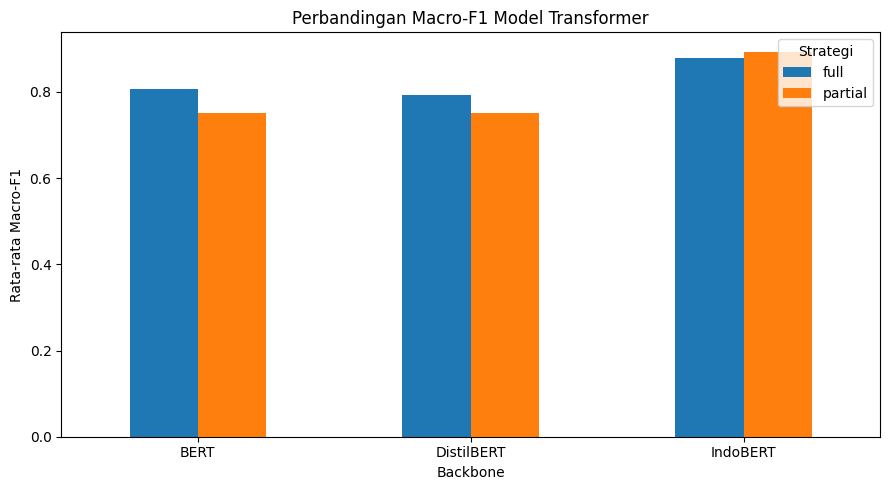

In [ ]:
import matplotlib.pyplot as plt

# Mengambil rata-rata Macro-F1
grafik_f1 = rekap.pivot(
    index="backbone",
    columns="strategi",
    values="macro_f1_mean"
)

grafik_f1.plot(kind="bar", figsize=(9, 5))

plt.title("Perbandingan Macro-F1 Model Transformer")
plt.xlabel("Backbone")
plt.ylabel("Rata-rata Macro-F1")
plt.xticks(rotation=0)
plt.legend(title="Strategi")
plt.tight_layout()
plt.show()

In [ ]:
# Memuat hasil akhir dari Google Drive
hasil_semua = pd.read_csv(
    folder_hasil / f"hasil_smsa_{kode}.csv"
)

rekap = pd.read_csv(
    folder_hasil / f"rekap_agregat_smsa_{kode}.csv"
)

# Memeriksa kelengkapan eksperimen
print("Total run:", len(hasil_semua))
print("Jumlah kombinasi:", len(rekap))

print("\nJumlah seed setiap kombinasi:")
jumlah_run = hasil_semua.groupby(
    ["backbone", "strategi"]
)["seed"].nunique()

display(jumlah_run)

assert len(hasil_semua) == 18
assert len(rekap) == 6
assert (jumlah_run == 3).all()

# Memeriksa nilai hasil eksperimen
kolom_metrik = [
    "accuracy",
    "macro_f1",
    "waktu_latih_detik",
    "inferensi_ms_per_kalimat",
    "parameter_total",
    "parameter_dilatih",
    "memori_puncak_mb"
]

assert not hasil_semua[kolom_metrik].isna().any().any()

print("\nSeluruh eksperimen lengkap!")
print("\nRekap hasil:")
display(rekap.round(4))

Total run: 18
Jumlah kombinasi: 6

Jumlah seed setiap kombinasi:


backbone    strategi
BERT        full        3
            partial     3
DistilBERT  full        3
            partial     3
IndoBERT    full        3
            partial     3
Name: seed, dtype: int64


Seluruh eksperimen lengkap!

Rekap hasil:


,backbone,strategi,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,waktu_latih_detik_mean,waktu_latih_detik_std,inferensi_ms_per_kalimat_mean,inferensi_ms_per_kalimat_std,parameter_total_mean,parameter_total_std,parameter_dilatih_mean,parameter_dilatih_std,memori_puncak_mb_mean,memori_puncak_mb_std
0,BERT,full,0.8507,0.0163,0.8058,0.0139,837.0508,1.9873,8.2116,0.0425,177855747.0,0.0,177855747.0,0.0,3426.9176,3.1656
1,BERT,partial,0.8013,0.0095,0.7522,0.0166,516.8705,0.2097,8.2156,0.0250,177855747.0,0.0,43120131.0,0.0,1676.6916,0.9465
2,DistilBERT,full,0.8340,0.0072,0.7925,0.0121,450.3489,0.6150,4.1304,0.0349,135326979.0,0.0,135326979.0,0.0,2609.0267,1.8764
3,DistilBERT,partial,0.7907,0.0266,0.7510,0.0177,232.5372,0.0406,3.6109,0.0112,135326979.0,0.0,21856515.0,0.0,1047.5841,0.6292
4,IndoBERT,full,0.9047,0.0140,0.8792,0.0194,733.6536,0.1864,7.1580,0.0021,124443651.0,0.0,124443651.0,0.0,2696.0627,0.7939
5,IndoBERT,partial,0.9187,0.0129,0.8937,0.0202,468.9096,0.2041,7.1589,0.0158,124443651.0,0.0,43120131.0,0.0,1473.1916,0.3819


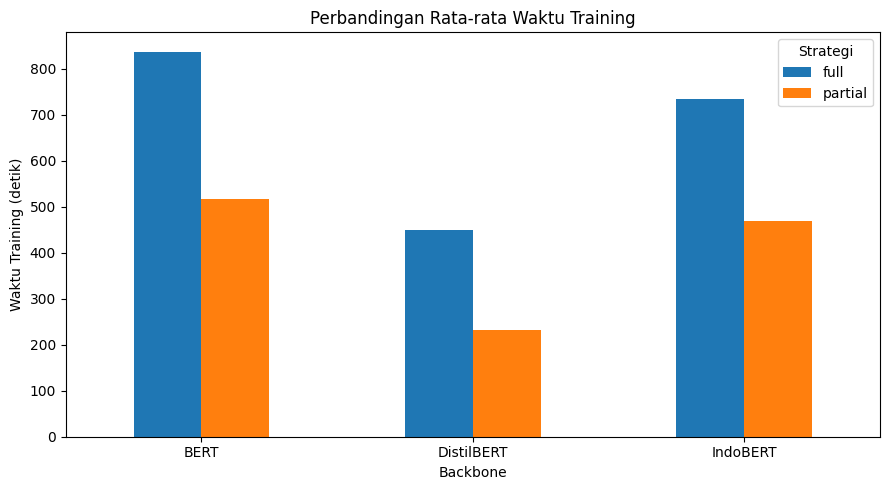

In [ ]:
import matplotlib.pyplot as plt

# Grafik waktu training
grafik_waktu = rekap.pivot(
    index="backbone",
    columns="strategi",
    values="waktu_latih_detik_mean"
)

grafik_waktu.plot(kind="bar", figsize=(9, 5))

plt.title("Perbandingan Rata-rata Waktu Training")
plt.xlabel("Backbone")
plt.ylabel("Waktu Training (detik)")
plt.xticks(rotation=0)
plt.legend(title="Strategi")
plt.tight_layout()
plt.show()

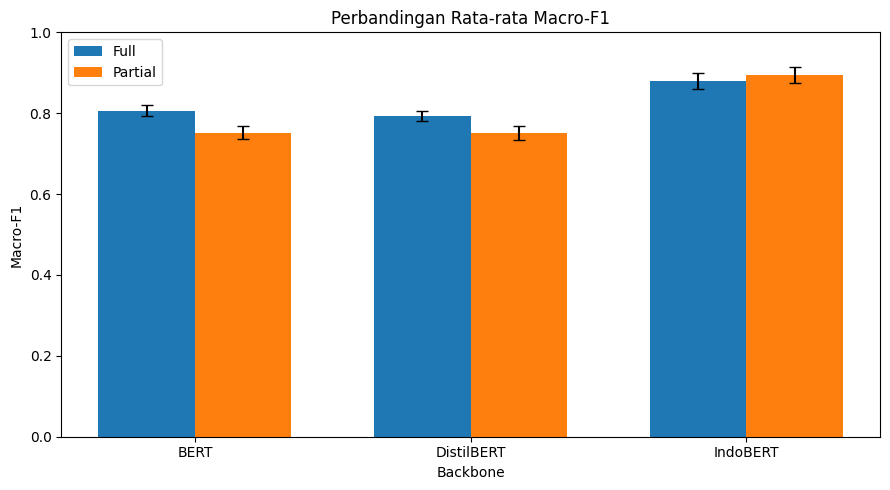

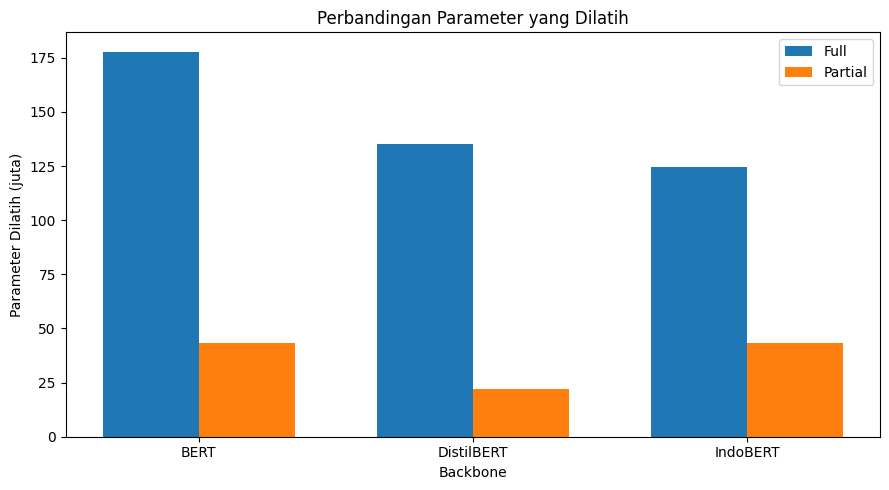

Grafik berhasil disimpan ke Google Drive.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

folder_evaluasi.mkdir(parents=True, exist_ok=True)

urutan_model = ["BERT", "DistilBERT", "IndoBERT"]
full = rekap[rekap["strategi"] == "full"].set_index("backbone")
partial = rekap[rekap["strategi"] == "partial"].set_index("backbone")

full = full.reindex(urutan_model)
partial = partial.reindex(urutan_model)

x = np.arange(len(urutan_model))
lebar = 0.35

# Grafik perbandingan Macro-F1
plt.figure(figsize=(9, 5))

plt.bar(x - lebar/2, full["macro_f1_mean"],
        lebar, yerr=full["macro_f1_std"],
        capsize=4, label="Full")

plt.bar(x + lebar/2, partial["macro_f1_mean"],
        lebar, yerr=partial["macro_f1_std"],
        capsize=4, label="Partial")

plt.xticks(x, urutan_model)
plt.xlabel("Backbone")
plt.ylabel("Macro-F1")
plt.title("Perbandingan Rata-rata Macro-F1")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig(folder_evaluasi / "grafik_macro_f1.png", dpi=150)
plt.show()

# Grafik jumlah parameter yang dilatih
plt.figure(figsize=(9, 5))

plt.bar(x - lebar/2, full["parameter_dilatih_mean"]/1e6,
        lebar, label="Full")

plt.bar(x + lebar/2, partial["parameter_dilatih_mean"]/1e6,
        lebar, label="Partial")

plt.xticks(x, urutan_model)
plt.xlabel("Backbone")
plt.ylabel("Parameter Dilatih (juta)")
plt.title("Perbandingan Parameter yang Dilatih")
plt.legend()
plt.tight_layout()
plt.savefig(folder_evaluasi / "grafik_parameter.png", dpi=150)
plt.show()

print("Grafik berhasil disimpan ke Google Drive.")

## 7. Pembahasan Hasil Eksperimen

Berdasarkan hasil eksperimen, IndoBERT menghasilkan rata-rata Macro-F1 tertinggi dibandingkan BERT Multilingual dan DistilBERT Multilingual. Pada strategi full fine-tuning, IndoBERT memperoleh Macro-F1 sebesar 0,8792, sedangkan pada partial freezing meningkat menjadi 0,8937.

BERT Multilingual memperoleh Macro-F1 sebesar 0,8058 pada full fine-tuning dan 0,7522 pada partial freezing. DistilBERT memperoleh Macro-F1 sebesar 0,7925 pada full fine-tuning dan 0,7510 pada partial freezing.

Dari sisi efisiensi, DistilBERT memiliki waktu pelatihan lebih rendah dibandingkan BERT pada strategi full fine-tuning. Hal ini menunjukkan adanya keuntungan penggunaan model dengan lapisan encoder yang lebih sedikit.

Penerapan partial freezing mengurangi jumlah parameter yang dilatih dan waktu pelatihan. Namun, dampaknya terhadap Macro-F1 tidak selalu sama. Pada BERT dan DistilBERT, full fine-tuning memperoleh hasil yang lebih tinggi. Sebaliknya, IndoBERT menghasilkan Macro-F1 lebih tinggi menggunakan partial freezing.

Hasil ini menunjukkan bahwa pemilihan strategi fine-tuning perlu mempertimbangkan karakteristik backbone serta keseimbangan antara kinerja klasifikasi dan kebutuhan komputasi.

## 8. Kesimpulan

Berdasarkan 18 eksperimen yang dilakukan menggunakan tiga backbone, dua strategi fine-tuning, dan tiga random seed, diperoleh beberapa kesimpulan.

IndoBERT menghasilkan kinerja klasifikasi sentimen terbaik pada dataset SmSA. Hasil tertinggi diperoleh melalui strategi partial freezing dengan rata-rata Macro-F1 sebesar 0,8937 ± 0,0202. Hasil ini mendukung hipotesis H1 bahwa model pretrained berbahasa Indonesia dapat memberikan kinerja yang lebih baik pada tugas klasifikasi sentimen Bahasa Indonesia.

Pada strategi full fine-tuning, DistilBERT membutuhkan waktu pelatihan lebih singkat dibandingkan BERT Multilingual, yaitu sekitar 450,35 detik dibandingkan 837,05 detik. Hasil tersebut mendukung hipotesis H2 mengenai efisiensi DistilBERT pada konfigurasi yang diuji.

Hipotesis H3 tidak sepenuhnya didukung. Full fine-tuning menghasilkan Macro-F1 lebih tinggi pada BERT dan DistilBERT, tetapi IndoBERT justru memperoleh hasil lebih tinggi menggunakan partial freezing. Dengan demikian, pelatihan seluruh parameter tidak selalu menghasilkan kinerja terbaik.

Secara keseluruhan, IndoBERT dengan partial freezing menjadi pilihan terbaik berdasarkan rata-rata Macro-F1 dalam eksperimen ini. Strategi tersebut juga mengurangi jumlah parameter yang perlu dilatih dibandingkan full fine-tuning.

Perbandingan waktu inferensi antarmodel yang dijalankan pada sesi Colab berbeda masih memiliki keterbatasan. Oleh karena itu, hasil waktu inferensi perlu ditafsirkan dengan mempertimbangkan kondisi perangkat dan sesi pengukuran.


## 9. Daftar Pustaka

1. Devlin, J., Chang, M. W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. DOI:
[10.18653/v1/N19-1423](https://aclanthology.org/N19-1423/)

2. Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). DistilBERT, a distilled version of BERT: Smaller, faster, cheaper and lighter. arXiv:1910.01108. DOI : [
https://doi.org/10.48550/arXiv.1910.01108
](https://arxiv.org/abs/1910.01108)

3. Wilie, B., et al. (2020). IndoNLU: Benchmark and Resources for Evaluating Indonesian Natural Language Understanding. Proceedings of AACL-IJCNLP. DOI :[10.18653/v1/2020.aacl-main.85](https://aclanthology.org/2020.aacl-main.85/)

4. Hugging Face. Transformers Documentation. https://huggingface.co/docs/transformers

5. IndoBenchmark. indobert-base-p1. https://huggingface.co/indobenchmark/indobert-base-p1
